In [1]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
sys.path.append('../')
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

from matplotlib import pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path
from scipy.optimize import curve_fit

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P']

In [ ]:
# closure test? i.e. there is truth pythia data somewhere to compare to
closure = True

# define binnings
n_bins = 9 #7 # WARNING RooUnfold seg faults if too many bins used
binning_reco = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500]).astype(float)
# binning_reco = np.array([10, 20, 40, 60, 80, 100, 150]).astype(float)
bincenters_reco = get_lin_bincenters(binning_reco)
binwidths_reco = np.array(get_binwidths(binning_reco))

n_bins_true = 9 #7 # WARNING RooUnfold seg faults if too many bins used
binning = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500]).astype(float)
# binning = binning = np.array([5, 10, 20, 40, 60, 80, 100]).astype(float)
bincenters = get_lin_bincenters(binning)
binwidths = np.array(get_binwidths(binning))

labels = "jet $p_T$"

n_iter = 5 #3

In [3]:
len(binning)

10

## Define files and histograms

In [4]:
# file defs, hist imports

f_unfolded = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D.root")
f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/60403841/response_groomed_forunfolding_merged.root")
f_preunfold_rm2 = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/60403841/response_groomed_merged_partial.root")
f_closure_tests = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D_tests.root")
f_raw_data = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/data/60320414/AnalysisResultsMerged_groomedbins.root")

# MC, true [theta0_G]
h1_gen_all = f_preunfold_rm["jet_all_gen_eff_den_groomed"] #"gen1D"]

# MC, reco
h1_reco_all = f_preunfold_rm["jet_all_rec_pur_den_groomed"] #"reco1D"]

# MC, true [theta0_G]
h1_gen_matched = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #"gen1D"]

# MC, reco
h1_reco_matched = f_preunfold_rm["jet_match_rec_pur_num_groomed"] #"reco1D"]

# Data, reco (raw)
# h1_raw = f_unfolded["groomed_sd0.1_jet_pt_raw1D"] # this is purity corrected!
h1_raw = f_raw_data["groomed_sd0.1_jet_pt_raw1D"]

# MC, original RM
# matrix = f_unfolded["matrix_{}".format(lab)].values()
matrix1D = f_unfolded["matrix1D"].values()
# matrix1D = f_preunfold_rm2["resp_jetpt_groomed"].values()


### Trivial closure ###
# MC matched, unfolded (new gen level)
h1_mc_matched_unfolded = []
for i in range(1,n_iter+1):
    h1_mc_matched_unfolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_Matched_Unfolded1Diter{}".format(i)])

# MC matched, refolded (new det level)
h1_mc_matched_refolded = []
for i in range(1,n_iter+1):
    h1_mc_matched_refolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_Matched_Refolded1Diter{}".format(i)])

# MC matched FROM RM, unfolded (new gen level)
h1_mc_matchedfromrms_unfolded = []
for i in range(1,n_iter+1):
    h1_mc_matchedfromrms_unfolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_MatchedFromRMs_Unfolded1Diter{}".format(i)])

# MC matched FROM RM, refolded (new det level)
h1_mc_matchedfromrms_refolded = []
for i in range(1,n_iter+1):
    h1_mc_matchedfromrms_refolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_MatchedFromRMs_Refolded1Diter{}".format(i)])

# MC all, unfolded (new gen level)
h1_mc_all_unfolded = []
for i in range(1,n_iter+1):
    h1_mc_all_unfolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_All_Unfolded1Diter{}".format(i)])

# MC all, refolded (new det level)
h1_mc_all_refolded = []
for i in range(1,n_iter+1):
    h1_mc_all_refolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_All_Refolded1Diter{}".format(i)])

# MC all, unfolded (new gen level), only eff on
h1_mc_all_onlyeffon_unfolded = []
for i in range(1,n_iter+1):
    h1_mc_all_onlyeffon_unfolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_All_OnlyEffOn_Unfolded1Diter{}".format(i)])

# MC all, refolded (new det level), only eff on
h1_mc_all_onlyeffon_refolded = []
for i in range(1,n_iter+1):
    h1_mc_all_onlyeffon_refolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_All_OnlyEffOn_Refolded1Diter{}".format(i)])

# MC all, unfolded (new gen level), only pur on
h1_mc_all_onlypuron_unfolded = []
for i in range(1,n_iter+1):
    h1_mc_all_onlypuron_unfolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_All_OnlyPurOn_Unfolded1Diter{}".format(i)])

# MC all, refolded (new det level), only pur on
h1_mc_all_onlypuron_refolded = []
for i in range(1,n_iter+1):
    h1_mc_all_onlypuron_refolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_All_OnlyPurOn_Refolded1Diter{}".format(i)])

# MC all, unfolded (new gen level), eff and pur off
h1_mc_all_effpuroff_unfolded = []
for i in range(1,n_iter+1):
    h1_mc_all_effpuroff_unfolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_All_EffPurOff_Unfolded1Diter{}".format(i)])

# MC all, refolded (new det level), eff and pur off
h1_mc_all_effpuroff_refolded = []
for i in range(1,n_iter+1):
    h1_mc_all_effpuroff_refolded.append(f_closure_tests["trivial_closure/Trivial_Baysian_All_EffPurOff_Refolded1Diter{}".format(i)])



### Refolding test ###
# Data, unfolded
h1_unfolded = []
for i in range(1,n_iter+1):
    h1_unfolded.append(f_closure_tests["refolding_closure/Baysian_Unfolded1Diter{}".format(i)])

# Data, refolded
h1_refolded = []
for i in range(1, n_iter+1):
    h1_refolded.append(f_closure_tests["refolding_closure/Baysian_Refolded1Diter{}".format(i)])

# # Data, refolded (no eff/pur in unfolding or refolding)
# h1_refolded_noeffpur = []
# for i in range(1, n_iter+1):
#     h1_refolded_noeffpur.append(f_closure_tests["refolding_closure/NoEffPur_Baysian_Refolded1Diter{}".format(i)])





# # Data, true [theta_unknown_G]
# if closure:
#     h1_true = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #"gen1D"]




In [5]:
def plot_closure_test(n_iter, bincenters, binning, binwidths, y_lines, y_points, y_points_err, L_colors, L_markers, label_lines, label_points, unfolding=True):
    # Plot refolding test in panels, with each panel covering one iteration

    fig, axs = plt.subplots(2, 5, figsize=(15, 6), sharex=True, sharey='row', gridspec_kw={'wspace': 0, 'hspace': 0})

    pt_lims = [0, 200]

    # fig.set_title("RooUnfold Refolding Test")

    for i in range(n_iter):
        # TOP PANEL - DISTRIBUTIONS
        ax = axs[0, i]
        # ax.scatter(bincenters, y_points[i] / binwidths, color=L_colors[i], marker=L_markers[i], label=label_points, lw=1) #"MC matched gen"
        ax.errorbar(bincenters, y_points[i] / binwidths, yerr=y_points_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color=L_colors[i], label=label_points)
        ax.step(binning[:-1], y_lines / binwidths, where="post", color=L_colors[i], label=label_lines, lw=1.8, ls='-') #"Unfolded MC"

        info_text = ("n_iter= {}".format(i+1)) #\n")
        ax.text(
            0.1, 0.15,               # x, y position (top-left)
            info_text,
            transform=ax.transAxes,   # Use axes coordinates (0,0 = bottom-left, 1,1 = top-right)
            fontsize=10,
            verticalalignment="top",
            horizontalalignment="left") #,bbox=bbox_props)

        ax.set_xlim(pt_lims)
        # ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(r"p_{T, jet}")
        if i == 0:
            ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$") #("#frac{dN}{dp_{T,jet}}")
        ax.legend(frameon=False)
        # ax.grid(True, which='both', linestyle=':', alpha=0.5)

        # BOTTOM PANEL - RATIO
        ax = axs[1, i]

        ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0)  # ±5% band
        
        yvals_ratio = safe_divide(y_points[i], y_lines, filler=1)
        ax.scatter(bincenters, yvals_ratio, color=L_colors[i], marker=L_markers[i], lw=1.5) #, where='post')
        yerrs_ratio = safe_divide(y_points_err[i], y_points[i])
        ax.fill_between(bincenters, (yvals_ratio-yerrs_ratio), (yvals_ratio+yerrs_ratio), alpha=0.4, edgecolor=L_colors[i], facecolor=L_colors[i], linewidth=0)
        
        ax.axhline(1.0, color='gray', linestyle='--')
        # ax.set_ylim(0.7, 1.3)

        ax.set_xlim(pt_lims)
        # ax.set_xscale("log")
        ax.set_xlabel(r"$p_{T, jet}$")
        if i == 0:
            if unfolding:
                ax.set_ylabel("Unfolded / Truth")
            else:
                ax.set_ylabel("Refolded / Raw")


    fig.tight_layout()
    plt.show()

In [6]:
def plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y_lines, y_points, L_colors, L_markers, label_lines, label_points, unfolding=True, extralabel=""):
    fig, axs = plt.subplots(2, 1, figsize=(6, 8), sharex=True,
                            gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
    pt_lims = [0, 200]

    # ---------------- TOP PANEL - DISTRIBUTIONS ----------------
    ax = axs[0]
    # Reference points: same for every iteration, so draw once
    print(y_lines)
    ax.step(binning[:-1], y_lines / binwidths, where="post", color='black',
            lw=1.8, ls='-', label=label_lines)
    
    for i in range(n_iter):
        ax.scatter(bincenters, y_points[i] / binwidths, color=L_colors[i], marker='o',
                       label=f"{label_points}, n_iter = {i+1}", zorder=3)

    ax.set_xlim(pt_lims)
    ax.set_yscale("log")
    ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
    ax.legend(frameon=False, fontsize=9)

    ax.text(0.1, 0.1, extralabel, transform=ax.transAxes, fontsize=10, verticalalignment="top", horizontalalignment="left") #,bbox=bbox_props)

    # ---------------- BOTTOM PANEL - RATIO ----------------
    ax = axs[1]
    ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
    ax.axhline(1.0, color='gray', linestyle='--', zorder=1)

    for i in range(n_iter):
        yvals_ratio = safe_divide(y_points[i], y_lines, filler=1)
        ax.scatter(bincenters, yvals_ratio, color=L_colors[i], marker=L_markers[i],
                   lw=1.5, zorder=2, label=f"n_iter = {i+1}")

    ax.set_xlim(pt_lims)
    ax.set_xlabel(r"$p_{T,\text{jet}}$")
    if unfolding:
        ax.set_ylabel("Unfolded / Truth")
    else:
        ax.set_ylabel("Refolded / Raw")
    ax.legend(frameon=False, fontsize=9, ncol=2)

    fig.tight_layout()
    plt.show()

## Quick test

There might be some overcounting of the efficiency and purity. Below, If Htruth / matched-truth proj is not 1 and instead matches 1/efficiency, that's the cause. The same holds for Hmeasured vs fakes and purity.


In [7]:
import ROOT
ROOT.gSystem.Load("/global/cfs/cdirs/alice/blianggi/mypyjetty/heppy/external/roounfold/roounfold-current/lib/libRooUnfold.so")
ROOT.gInterpreter.AddIncludePath("/global/cfs/cdirs/alice/blianggi/mypyjetty/heppy/external/roounfold/roounfold-current/include")
ROOT.gInterpreter.Declare('#include "RooUnfoldResponse.h"')

Welcome to JupyROOT 6.28/06


True

In [8]:
ft  = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D_tests.root")
frm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/58919321/response_groomed_forunfolding_merged.root")

M = ft["matrix1D"].values(flow=True)        # shape (nreco+2, ntruth+2); reco on x, truth on y
htruth = ft["trivial_closure/gen_MatchedFromRMs_input"].values()   # = Htruth()
hmeas  = ft["trivial_closure/rec_MatchedFromRMs_input"].values()   # = Hmeasured()
gen_num = frm["jet_match_gen_eff_num_groomed"].values()
rec_num = frm["jet_match_rec_pur_num_groomed"].values()
unf1 = ft["trivial_closure/Trivial_Baysian_MatchedFromRMs_Unfolded1Diter1"].values()

reco_truth_in  = M[1:-1, 1:-1].sum(axis=1)   # reco projection, truth in range only
reco_truth_all = M[1:-1, :].sum(axis=1)      # reco projection, incl. truth under/overflow
truth_reco_in  = M[1:-1, 1:-1].sum(axis=0)   # truth projection, reco in range only
truth_reco_all = M[:, 1:-1].sum(axis=0)      # truth projection, incl. reco under/overflow

def r(a, b):
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.round(a / b, 4)

print("Hmeasured / reco(truth in) :", r(hmeas, reco_truth_in))
print("Hmeasured / reco(truth all):", r(hmeas, reco_truth_all))
print("rec_num   / reco(truth all):", r(rec_num, reco_truth_all))
print("Htruth    / truth(reco all):", r(htruth, truth_reco_all))
print("Htruth    / truth(reco in) :", r(htruth, truth_reco_in))
print("gen_num   / truth(reco all):", r(gen_num, truth_reco_all))
print("Unfolded iter1 / Htruth    :", r(unf1, htruth))

print("truth underflow row (reco in range):", M[1:-1, 0].sum())
print("truth overflow row  (reco in range):", M[1:-1, -1].sum())
print("reco underflow col  (truth in range):", M[0, 1:-1].sum())
print("reco overflow col   (truth in range):", M[-1, 1:-1].sum())
print("total in-range entries:", M[1:-1, 1:-1].sum())

Hmeasured / reco(truth in) : [1.0259 1.0009 1.0004 1.0006 1.     1.     1.     1.0001 1.0009]
Hmeasured / reco(truth all): [1. 1. 1. 1. 1. 1. 1. 1. 1.]
rec_num   / reco(truth all): [0.9901 0.9943 0.9965 0.9971 0.9978 0.9982 0.9985 0.9989 0.9996]
Htruth    / truth(reco all): [1. 1. 1. 1. 1. 1. 1. 1. 1.]
Htruth    / truth(reco in) : [1.3749 1.0361 1.008  1.0047 1.0037 1.0034 1.0034 1.0037 1.0049]
gen_num   / truth(reco all): [0.9876 0.9923 0.9956 0.9968 0.9974 0.9978 0.998  0.9984 0.9993]
Unfolded iter1 / Htruth    : [1.0259 1.0122 1.0025 1.0015 1.0011 1.0009 1.0008 1.0008 1.001 ]
truth underflow row (reco in range): 14271.690742520857
truth overflow row  (reco in range): 0.0010672633519561714
reco underflow col  (truth in range): 196730.93471643838
reco overflow col   (truth in range): 0.0
total in-range entries: 592710.1118840826


In [10]:
raw = h1_raw.values(); err = h1_raw.errors()
pur = f_closure_tests["purity"].values()
d = raw * pur; derr = err * pur
rf5 = f_closure_tests["refolding_closure/Baysian_Refolded1Diter5"].values() * pur  # undo the /purity
print("pull per bin:", np.round((rf5 - d) / derr, 1))

pull per bin: [ -1.8   9.1 -11.8   5.    0.1  -1.5   1.    0.7   0.2]


In [11]:
mc = f_preunfold_rm["jet_match_rec_pur_num_groomed"].values()   # = Hmeasured
ratio = (d / d.sum()) / (mc / mc.sum())
print(np.round(ratio, 3))

[1.    0.987 1.109 1.19  1.284 1.36  1.331 1.299 1.258]


In [12]:
m = f_unfolded["matrix1D"]
w, var = m.values(), m.variances()
with np.errstate(divide="ignore", invalid="ignore"):
    neff = np.where(var > 0, w**2 / var, 0)
print("N_eff reco projection :", np.round(neff.sum(axis=1)))
print("N_eff truth projection:", np.round(neff.sum(axis=0)))

N_eff reco projection : [1490193. 2477540. 2141891. 1502418. 1009310.  645301.  529450.  308287.
   82310.]
N_eff truth projection: [ 672057. 1677509. 1748188. 1464572. 1129498.  855278.  902515.  886678.
  850406.]


## Trivial Closure Test

Take the MC reco (h1_reco) --> unfold it (h1_mc_unfolded) --> compare resulting *unfolded* distribution with original truth level MC (h1_mc_unfolded vs h1_gen)

Take the MC unfolded (h1_mc_unfolded) --> refold it with original RM (h1_mc_refolded) --> compare resulting *refolded* distribution with original detector level MC (h1_mc_refolded vs h1_reco)
*Note: use the matched distributions for perfect closure*

Need:
- MC reco (h1_reco)
- unfolded MC distribution (truth level MC) (h1_mc_unfolded)
- MC gen (h1_gen)
- refolded MC distribution (det level MC) (h1_mc_refolded)

In [ ]:
proj = lambda a : a.values()
proj_err = lambda a : a.errors()
proj_err_unf = lambda a : np.sqrt(a.errors()**2 + a.values())

# Extract 1D array values
y_gen_all = h1_gen_all.values() if hasattr(h1_gen_all, "values") else h1_gen_all
y_reco_all = h1_reco_all.values() if hasattr(h1_reco_all, "values") else h1_reco_all
y_gen_matched = h1_gen_matched.values() if hasattr(h1_gen_matched, "values") else h1_gen_matched
y_reco_matched = h1_reco_matched.values() if hasattr(h1_reco_matched, "values") else h1_reco_matched


y_mc_matched_unfolded = [proj(a) for a in h1_mc_matched_unfolded]
y_mc_matched_refolded = [proj(a) for a in h1_mc_matched_refolded]
y_mc_matchedfromrms_unfolded = [proj(a) for a in h1_mc_matchedfromrms_unfolded]
y_mc_matchedfromrms_refolded = [proj(a) for a in h1_mc_matchedfromrms_refolded]

y_mc_all_unfolded = [proj(a) for a in h1_mc_all_unfolded]
y_mc_all_refolded = [proj(a) for a in h1_mc_all_refolded]
y_mc_all_onlyeffon_unfolded = [proj(a) for a in h1_mc_all_onlyeffon_unfolded]
y_mc_all_onlyeffon_refolded = [proj(a) for a in h1_mc_all_onlyeffon_refolded]
y_mc_all_onlypuron_unfolded = [proj(a) for a in h1_mc_all_onlypuron_unfolded]
y_mc_all_onlypuron_refolded = [proj(a) for a in h1_mc_all_onlypuron_refolded]
y_mc_all_effpuroff_unfolded = [proj(a) for a in h1_mc_all_effpuroff_unfolded]
y_mc_all_effpuroff_refolded = [proj(a) for a in h1_mc_all_effpuroff_refolded]

# Projection of RM
y1_proj_matrix1D_reco = matrix1D.sum(axis=1)
y1_proj_matrix1D_gen = matrix1D.sum(axis=0) 


[5.12834334e+05 6.95942007e+04 3.83963659e+03 5.73452252e+02
 1.37282622e+02 4.29478800e+01 1.98739722e+01 7.17464812e+00
 1.84473508e+00]


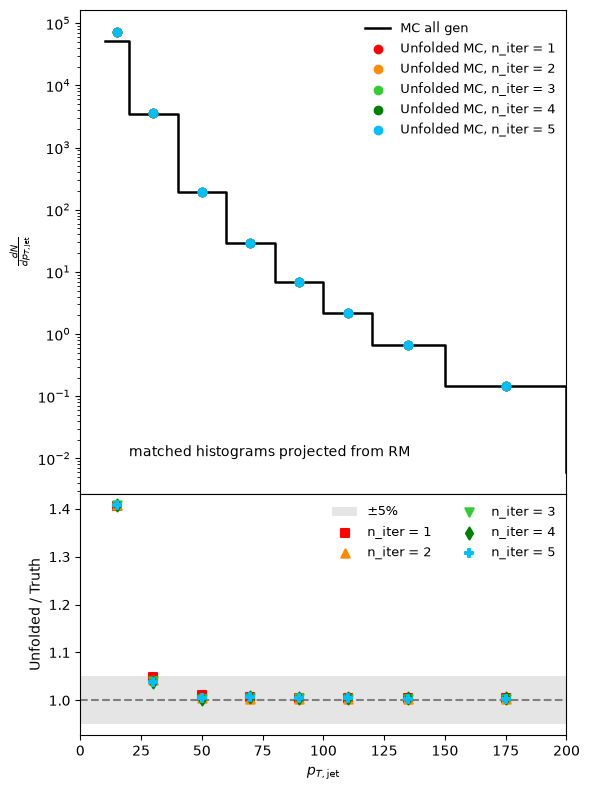

[5.43113788e+05 4.15723646e+04 1.99982767e+03 2.77675311e+02
 6.12381849e+01 1.76399818e+01 6.52397999e+00 1.53446838e+00
 1.54783427e-01]


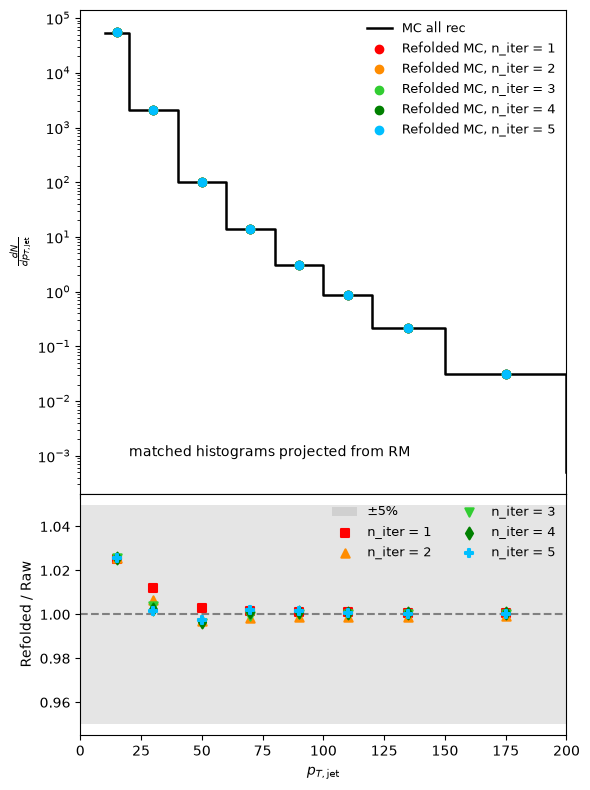

In [14]:
# Matched trivial unfolding & refolding (taking distributions from RMs)
# plot_closure_test(n_iter, bincenters, binning, binwidths, y1_proj_matrix1D_gen, y_mc_matchedfromrms_unfolded, L_colors, L_markers, "MC matched gen from RM", "Unfolded MC from RM")
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y1_proj_matrix1D_gen, y_mc_matchedfromrms_unfolded, L_colors, L_markers, "MC all gen", "Unfolded MC", True, "matched histograms projected from RM")
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y1_proj_matrix1D_reco, y_mc_matchedfromrms_refolded, L_colors, L_markers, "MC all rec", "Refolded MC", False, "matched histograms projected from RM")


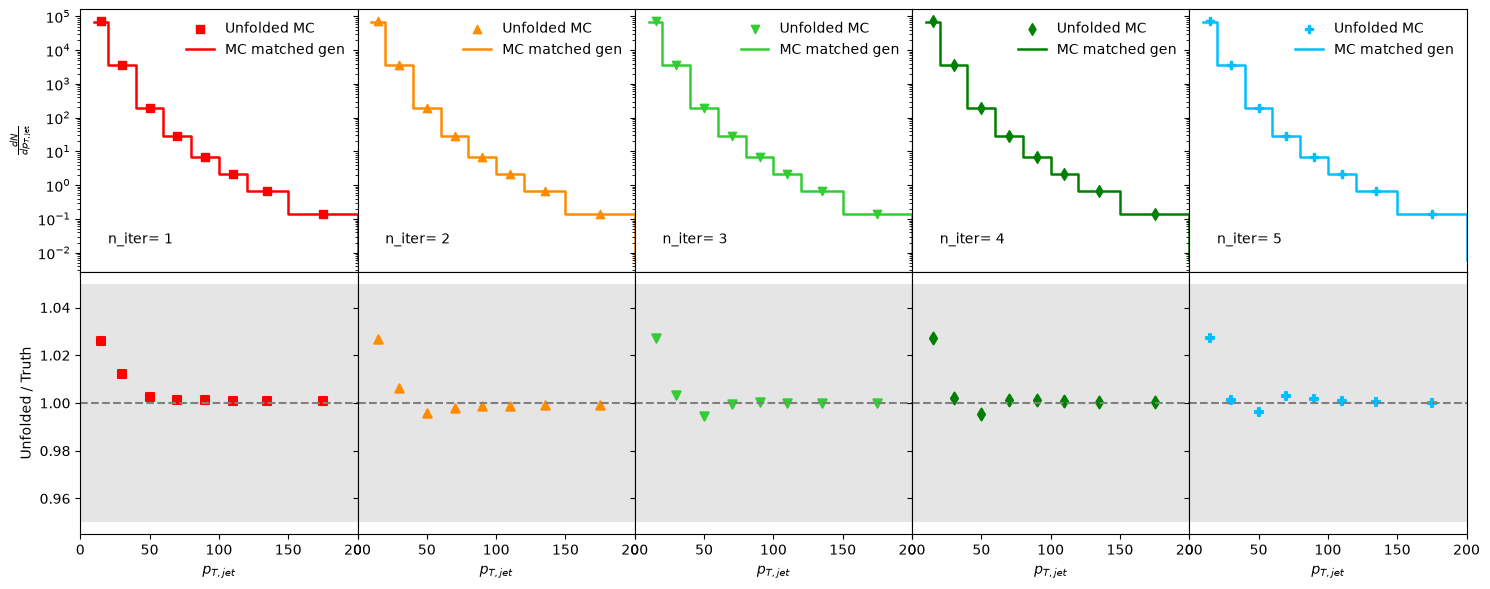

In [15]:
# Matched trivial unfolding
plot_closure_test(n_iter, bincenters, binning, binwidths, y_gen_matched, y_mc_matched_unfolded, L_colors, L_markers, "MC matched gen", "Unfolded MC", True)


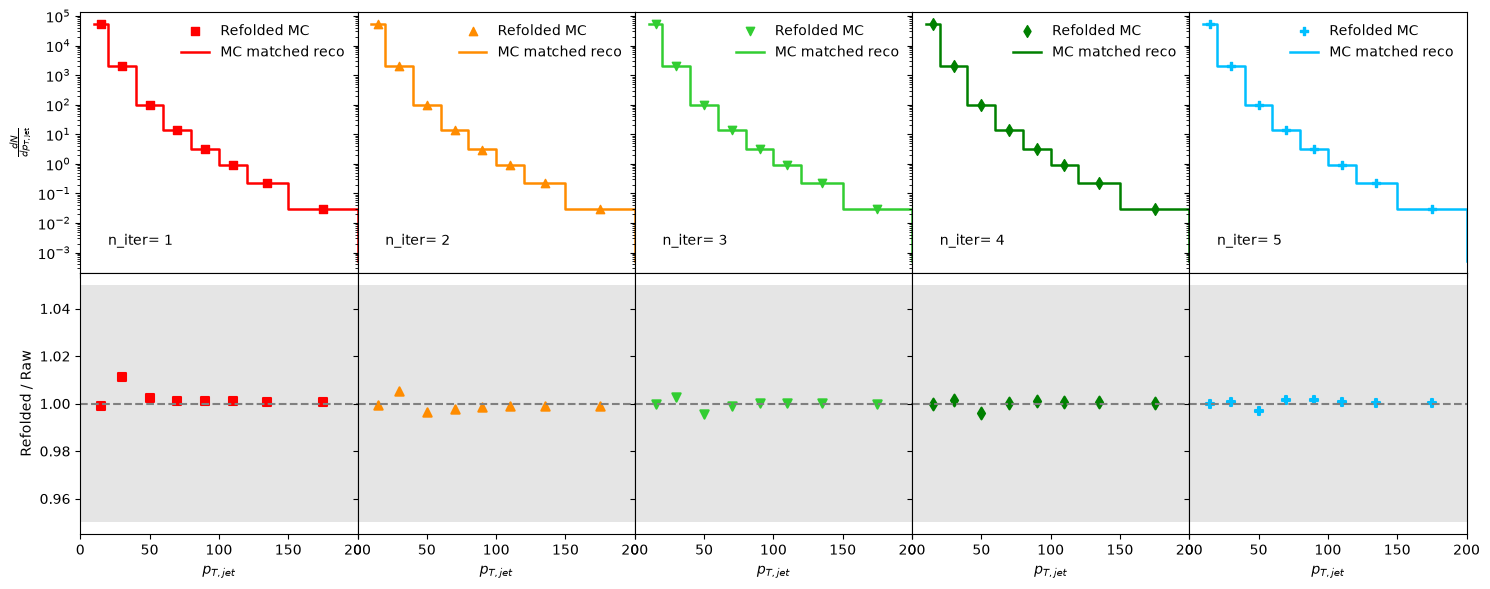

In [16]:
# Matched trivial refolding
plot_closure_test(n_iter, bincenters, binning, binwidths, y_reco_matched, y_mc_matched_refolded, L_colors, L_markers, "MC matched reco", "Refolded MC", False)


[1.05761909e+06 8.10967326e+04 4.13869642e+03 6.12678956e+02
 1.46943608e+02 4.65407242e+01 2.21718644e+01 8.49004960e+00
 2.39757851e+00]


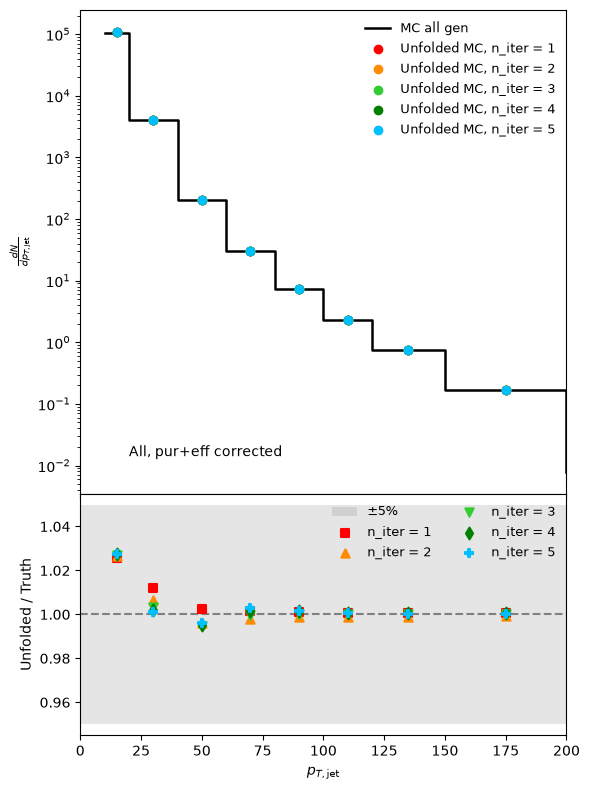

In [17]:
# All trivial unfolding
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y_gen_all, y_mc_all_unfolded, L_colors, L_markers, "MC all gen", "Unfolded MC", True, "All, pur+eff corrected")


[5.96065209e+05 4.80753047e+04 2.26173524e+03 3.08082039e+02
 6.62579711e+01 1.89342834e+01 6.89832371e+00 1.60495931e+00
 1.58510572e-01]


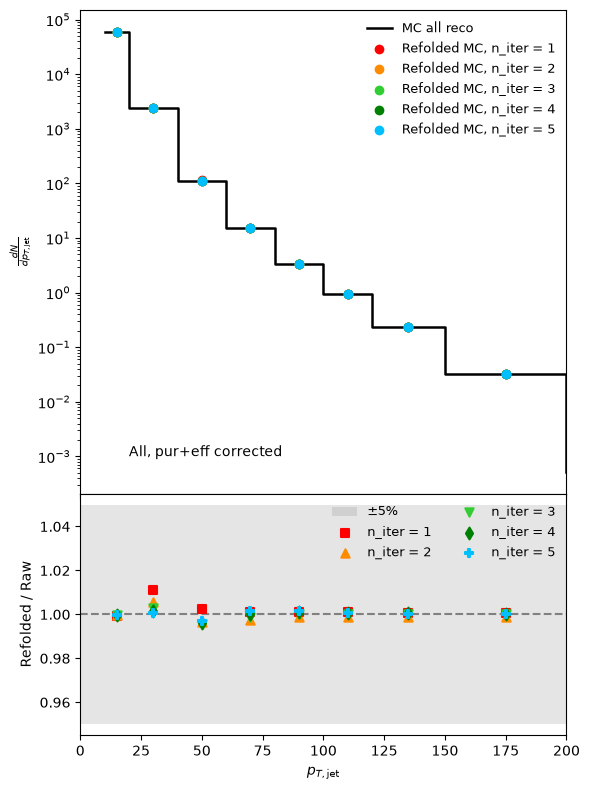

In [18]:
# All trivial refolding
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y_reco_all, y_mc_all_refolded, L_colors, L_markers, "MC all reco", "Refolded MC", False, "All, pur+eff corrected")


[1.05761909e+06 8.10967326e+04 4.13869642e+03 6.12678956e+02
 1.46943608e+02 4.65407242e+01 2.21718644e+01 8.49004960e+00
 2.39757851e+00]


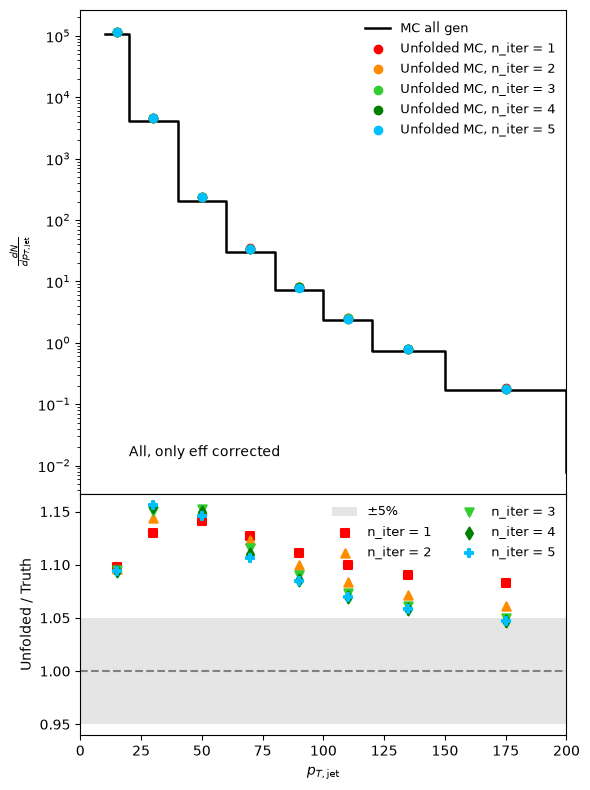

In [19]:
# All (only efficiency correction on) trivial refolding
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y_gen_all, y_mc_all_onlyeffon_unfolded, L_colors, L_markers, "MC all gen", "Unfolded MC", True, "All, only eff corrected")


[5.96065209e+05 4.80753047e+04 2.26173524e+03 3.08082039e+02
 6.62579711e+01 1.89342834e+01 6.89832371e+00 1.60495931e+00
 1.58510572e-01]


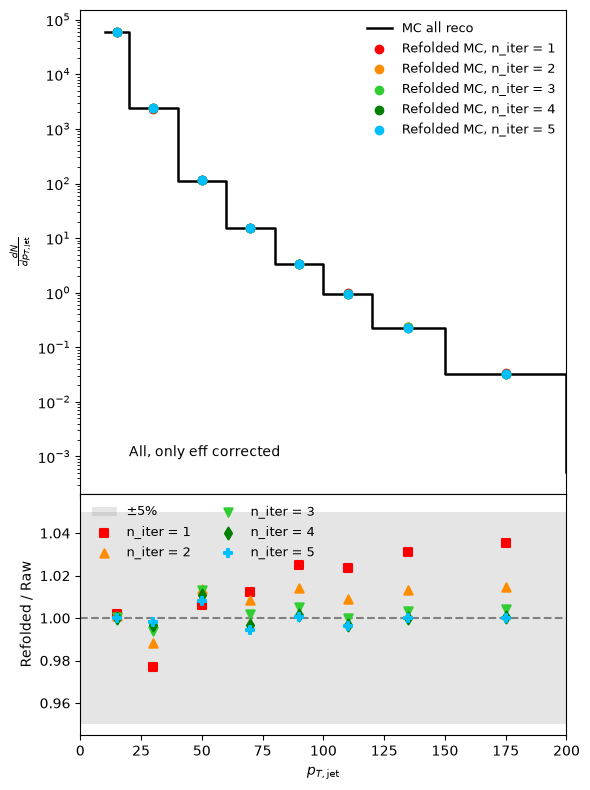

In [20]:
# All (only efficiency correction on) trivial refolding
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y_reco_all, y_mc_all_onlyeffon_refolded, L_colors, L_markers, "MC all reco", "Refolded MC", False, "All, only eff corrected")


[1.05761909e+06 8.10967326e+04 4.13869642e+03 6.12678956e+02
 1.46943608e+02 4.65407242e+01 2.21718644e+01 8.49004960e+00
 2.39757851e+00]


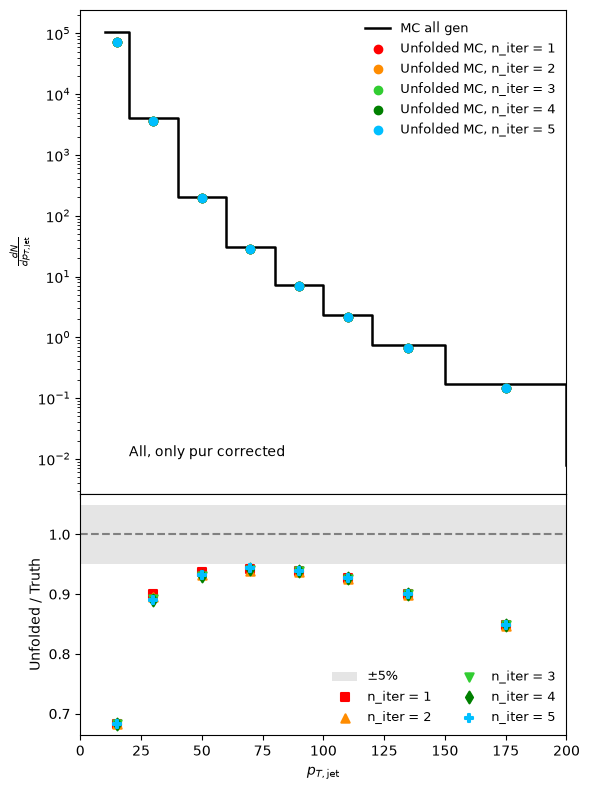

In [21]:
# All (only purity correction on) trivial refolding
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y_gen_all, y_mc_all_onlypuron_unfolded, L_colors, L_markers, "MC all gen", "Unfolded MC", True, "All, only pur corrected")


[5.96065209e+05 4.80753047e+04 2.26173524e+03 3.08082039e+02
 6.62579711e+01 1.89342834e+01 6.89832371e+00 1.60495931e+00
 1.58510572e-01]


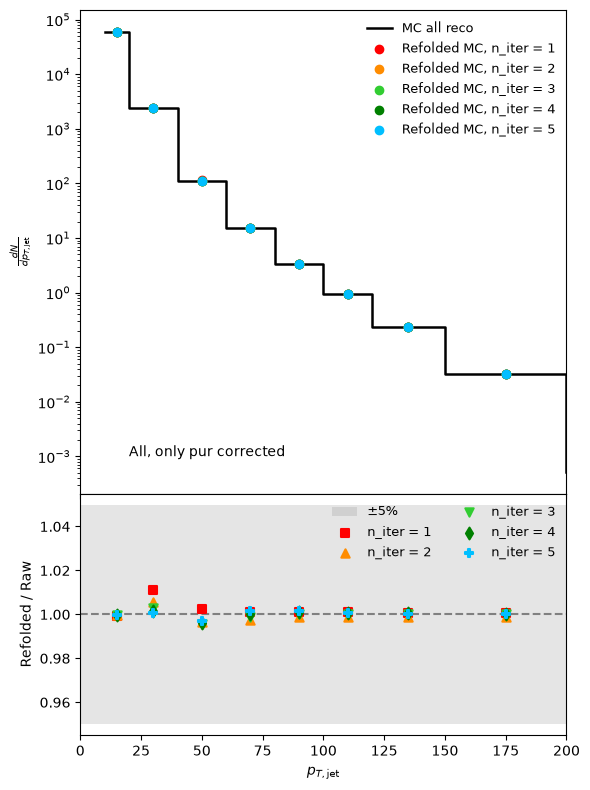

In [22]:
# All (only purity correction on) trivial refolding
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y_reco_all, y_mc_all_onlypuron_refolded, L_colors, L_markers, "MC all reco", "Refolded MC", False, "All, only pur corrected")


[1.05761909e+06 8.10967326e+04 4.13869642e+03 6.12678956e+02
 1.46943608e+02 4.65407242e+01 2.21718644e+01 8.49004960e+00
 2.39757851e+00]


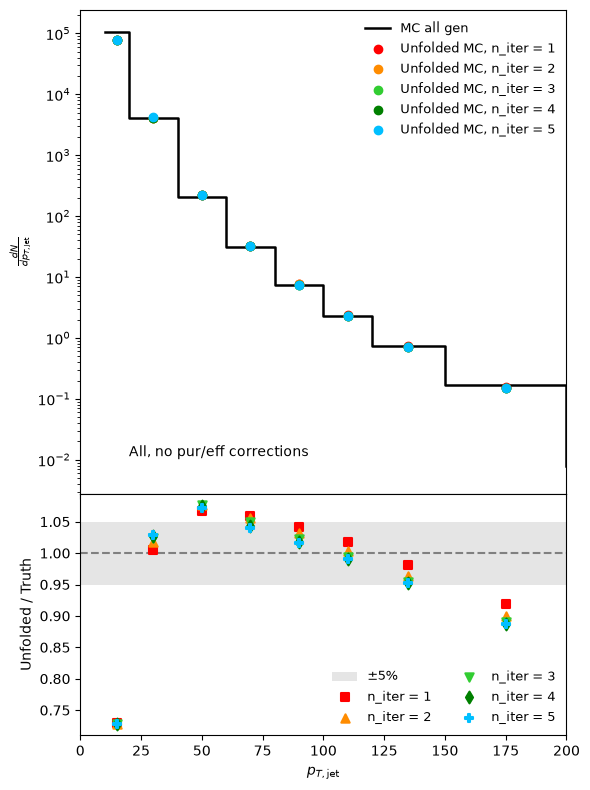

In [23]:
# All (purity and efficiency corrections off) trivial refolding
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y_gen_all, y_mc_all_effpuroff_unfolded, L_colors, L_markers, "MC all gen", "Unfolded MC", True, "All, no pur/eff corrections")


[5.96065209e+05 4.80753047e+04 2.26173524e+03 3.08082039e+02
 6.62579711e+01 1.89342834e+01 6.89832371e+00 1.60495931e+00
 1.58510572e-01]


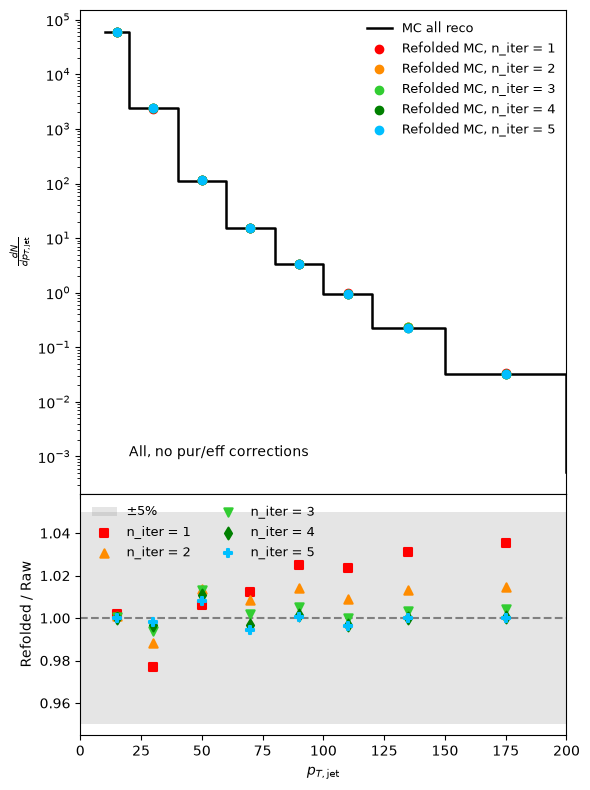

In [24]:
# All (purity and efficiency corrections off) trivial refolding
plot_closure_test_singleplot(n_iter, bincenters, binning, binwidths, y_reco_all, y_mc_all_effpuroff_refolded, L_colors, L_markers, "MC all reco", "Refolded MC", False, "All, no pur/eff corrections")


In [25]:
rec_Matched_input = f_closure_tests['trivial_closure/rec_Matched_input']
gen_Matched_input = f_closure_tests['trivial_closure/gen_Matched_input']
rec_work_Matched = f_closure_tests['trivial_closure/rec_work_Matched']
gen_work_Matched = f_closure_tests['trivial_closure/gen_work_Matched']

rec_MatchedFromRMs_input = f_closure_tests['trivial_closure/rec_MatchedFromRMs_input']
gen_MatchedFromRMs_input = f_closure_tests['trivial_closure/gen_MatchedFromRMs_input']
rec_work_MatchedFromRMs = f_closure_tests['trivial_closure/rec_work_MatchedFromRMs']
gen_work_MatchedFromRMs = f_closure_tests['trivial_closure/gen_work_MatchedFromRMs']

rec_All_input = f_closure_tests['trivial_closure/rec_All_input']
gen_All_input = f_closure_tests['trivial_closure/gen_All_input']
rec_work_All = f_closure_tests['trivial_closure/rec_work_All']
gen_work_All = f_closure_tests['trivial_closure/gen_work_All']

rec_All_EffPurOff_input = f_closure_tests['trivial_closure/rec_All_EffPurOff_input']
gen_All_EffPurOff_input = f_closure_tests['trivial_closure/gen_All_EffPurOff_input']
rec_work_All_EffPurOff = f_closure_tests['trivial_closure/rec_work_All_EffPurOff']
gen_work_All_EffPurOff = f_closure_tests['trivial_closure/gen_work_All_EffPurOff']


rec_All_OnlyEffOn_input = f_closure_tests['trivial_closure/rec_All_OnlyEffOn_input']
gen_All_OnlyEffOn_input = f_closure_tests['trivial_closure/gen_All_OnlyEffOn_input']
rec_work_All_OnlyEffOn = f_closure_tests['trivial_closure/rec_work_All_OnlyEffOn']
gen_work_All_OnlyEffOn = f_closure_tests['trivial_closure/gen_work_All_OnlyEffOn']

rec_All_OnlyPurOn_input = f_closure_tests['trivial_closure/rec_All_OnlyPurOn_input']
gen_All_OnlyPurOn_input = f_closure_tests['trivial_closure/gen_All_OnlyPurOn_input']
rec_work_All_OnlyPurOn = f_closure_tests['trivial_closure/rec_work_All_OnlyPurOn']
gen_work_All_OnlyPurOn = f_closure_tests['trivial_closure/gen_work_All_OnlyPurOn']

In [26]:
y_rec_Matched_input = rec_Matched_input.values()
y_gen_Matched_input = gen_Matched_input.values()
y_rec_work_Matched = rec_work_Matched.values()
y_gen_work_Matched = gen_work_Matched.values()

y_rec_MatchedFromRMs_input = rec_MatchedFromRMs_input.values()
y_gen_MatchedFromRMs_input = gen_MatchedFromRMs_input.values()
y_rec_work_MatchedFromRMs = rec_work_MatchedFromRMs.values()
y_gen_work_MatchedFromRMs = gen_work_MatchedFromRMs.values()

y_rec_All_input = rec_All_input.values()
y_gen_All_input = gen_All_input.values()
y_rec_work_All = rec_work_All.values()
y_gen_work_All = gen_work_All.values()

y_rec_All_EffPurOff_input = rec_All_EffPurOff_input.values()
y_gen_All_EffPurOff_input = gen_All_EffPurOff_input.values()
y_rec_work_All_EffPurOff = rec_work_All_EffPurOff.values()
y_gen_work_All_EffPurOff = gen_work_All_EffPurOff.values()


y_rec_All_OnlyEffOn_input = rec_All_OnlyEffOn_input.values()
y_gen_All_OnlyEffOn_input = gen_All_OnlyEffOn_input.values()
y_rec_work_All_OnlyEffOn = rec_work_All_OnlyEffOn.values()
y_gen_work_All_OnlyEffOn = gen_work_All_OnlyEffOn.values()

y_rec_All_OnlyPurOn_input = rec_All_OnlyPurOn_input.values()
y_gen_All_OnlyPurOn_input = gen_All_OnlyPurOn_input.values()
y_rec_work_All_OnlyPurOn = rec_work_All_OnlyPurOn.values()
y_gen_work_All_OnlyPurOn = gen_work_All_OnlyPurOn.values()

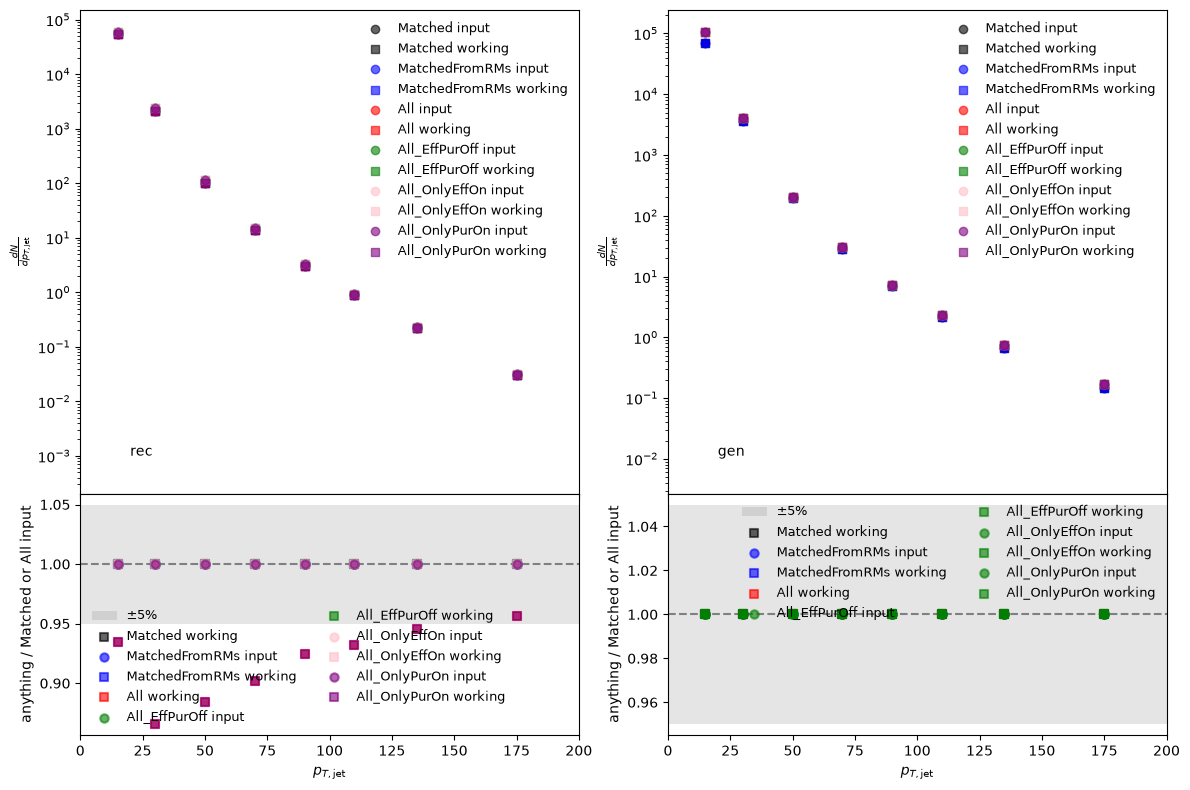

In [27]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True,
                        gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
pt_lims = [0, 200]

# ---------------- TOP PANEL - DISTRIBUTIONS ----------------
ax = axs[0,0]
# Reference points: same for every iteration, so draw once
# ax.step(binning[:-1], y_lines / binwidths, where="post", color='black',
#         lw=1.8, ls='-', label=label_lines)

ax.scatter(bincenters, y_rec_Matched_input / binwidths, color='black', marker='o', alpha=0.6, label="Matched input", zorder=3)
ax.scatter(bincenters, y_rec_work_Matched / binwidths, color='black', marker='s', alpha=0.6, label="Matched working", zorder=3)
ax.scatter(bincenters, y_rec_MatchedFromRMs_input / binwidths, color='blue', marker='o', alpha=0.6, label="MatchedFromRMs input", zorder=3)
ax.scatter(bincenters, y_rec_work_MatchedFromRMs / binwidths, color='blue', marker='s', alpha=0.6, label="MatchedFromRMs working", zorder=3)
ax.scatter(bincenters, y_rec_All_input / binwidths, color='red', marker='o', alpha=0.6, label="All input", zorder=3)
ax.scatter(bincenters, y_rec_work_All / binwidths, color='red', marker='s', alpha=0.6, label="All working", zorder=3)
ax.scatter(bincenters, y_rec_All_EffPurOff_input / binwidths, color='green', marker='o', alpha=0.6, label="All_EffPurOff input", zorder=3)
ax.scatter(bincenters, y_rec_work_All_EffPurOff / binwidths, color='green', marker='s', alpha=0.6, label="All_EffPurOff working", zorder=3)

ax.scatter(bincenters, y_rec_All_OnlyEffOn_input / binwidths, color='pink', marker='o', alpha=0.6, label="All_OnlyEffOn input", zorder=3)
ax.scatter(bincenters, y_rec_work_All_OnlyEffOn / binwidths, color='pink', marker='s', alpha=0.6, label="All_OnlyEffOn working", zorder=3)
ax.scatter(bincenters, y_rec_All_OnlyPurOn_input / binwidths, color='purple', marker='o', alpha=0.6, label="All_OnlyPurOn input", zorder=3)
ax.scatter(bincenters, y_rec_work_All_OnlyPurOn / binwidths, color='purple', marker='s', alpha=0.6, label="All_OnlyPurOn working", zorder=3)

ax.set_xlim(pt_lims)
ax.set_yscale("log")
ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

ax.text(0.1, 0.1, "rec", transform=ax.transAxes, fontsize=10, verticalalignment="top", horizontalalignment="left") #,bbox=bbox_props)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1,0]
ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)

yvals_ratio = safe_divide(y_rec_work_Matched, y_rec_Matched_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='black', marker='s', alpha=0.6, lw=1.5, zorder=2, label="Matched working")
yvals_ratio = safe_divide(y_rec_MatchedFromRMs_input, y_rec_Matched_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='blue', marker='o', alpha=0.6, lw=1.5, zorder=2, label="MatchedFromRMs input")
yvals_ratio = safe_divide(y_rec_work_MatchedFromRMs, y_rec_Matched_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='blue', marker='s', alpha=0.6, lw=1.5, zorder=2, label="MatchedFromRMs working")

yvals_ratio = safe_divide(y_rec_work_All, y_rec_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='red', marker='s', alpha=0.6, lw=1.5, zorder=2, label="All working")
yvals_ratio = safe_divide(y_rec_All_EffPurOff_input, y_rec_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='green', marker='o', alpha=0.6, lw=1.5, zorder=2, label="All_EffPurOff input")
yvals_ratio = safe_divide(y_rec_work_All_EffPurOff, y_rec_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='green', marker='s', alpha=0.6, lw=1.5, zorder=2, label="All_EffPurOff working")


yvals_ratio = safe_divide(y_rec_All_OnlyEffOn_input, y_rec_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='pink', marker='o', alpha=0.6, lw=1.5, zorder=2, label="All_OnlyEffOn input")
yvals_ratio = safe_divide(y_rec_work_All_OnlyEffOn, y_rec_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='pink', marker='s', alpha=0.6, lw=1.5, zorder=2, label="All_OnlyEffOn working")

yvals_ratio = safe_divide(y_rec_All_OnlyPurOn_input, y_rec_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='purple', marker='o', alpha=0.6, lw=1.5, zorder=2, label="All_OnlyPurOn input")
yvals_ratio = safe_divide(y_rec_work_All_OnlyPurOn, y_rec_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='purple', marker='s', alpha=0.6, lw=1.5, zorder=2, label="All_OnlyPurOn working")

ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")

ax.set_ylabel("anything / Matched or All input")
# else:
#     ax.set_ylabel("Refolded / Raw")
ax.legend(frameon=False, fontsize=9, ncol=2)

# ---------------- TOP RIGHT PANEL - DISTRIBUTIONS----------------
ax = axs[0,1]
# Reference points: same for every iteration, so draw once
# ax.step(binning[:-1], y_lines / binwidths, where="post", color='black',
#         lw=1.8, ls='-', label=label_lines)

ax.scatter(bincenters, y_gen_Matched_input / binwidths, color='black', marker='o', alpha=0.6, label="Matched input", zorder=3)
ax.scatter(bincenters, y_gen_work_Matched / binwidths, color='black', marker='s', alpha=0.6, label="Matched working", zorder=3)
ax.scatter(bincenters, y_gen_MatchedFromRMs_input / binwidths, color='blue', marker='o', alpha=0.6, label="MatchedFromRMs input", zorder=3)
ax.scatter(bincenters, y_gen_work_MatchedFromRMs / binwidths, color='blue', marker='s', alpha=0.6, label="MatchedFromRMs working", zorder=3)
ax.scatter(bincenters, y_gen_All_input / binwidths, color='red', marker='o', alpha=0.6, label="All input", zorder=3)
ax.scatter(bincenters, y_gen_work_All / binwidths, color='red', marker='s', alpha=0.6, label="All working", zorder=3)
ax.scatter(bincenters, y_gen_All_EffPurOff_input / binwidths, color='green', marker='o', alpha=0.6, label="All_EffPurOff input", zorder=3)
ax.scatter(bincenters, y_gen_work_All_EffPurOff / binwidths, color='green', marker='s', alpha=0.6, label="All_EffPurOff working", zorder=3)

ax.scatter(bincenters, y_gen_All_OnlyEffOn_input / binwidths, color='pink', marker='o', alpha=0.6, label="All_OnlyEffOn input", zorder=3)
ax.scatter(bincenters, y_gen_work_All_OnlyEffOn / binwidths, color='pink', marker='s', alpha=0.6, label="All_OnlyEffOn working", zorder=3)
ax.scatter(bincenters, y_gen_All_OnlyPurOn_input / binwidths, color='purple', marker='o', alpha=0.6, label="All_OnlyPurOn input", zorder=3)
ax.scatter(bincenters, y_gen_work_All_OnlyPurOn / binwidths, color='purple', marker='s', alpha=0.6, label="All_OnlyPurOn working", zorder=3)

ax.set_xlim(pt_lims)
ax.set_yscale("log")
ax.set_ylabel(r"$\frac{dN}{dp_{T,\text{jet}}}$")
ax.legend(frameon=False, fontsize=9)

ax.text(0.1, 0.1, "gen", transform=ax.transAxes, fontsize=10, verticalalignment="top", horizontalalignment="left") #,bbox=bbox_props)

# ---------------- BOTTOM PANEL - RATIO ----------------
ax = axs[1,1]
ax.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
ax.axhline(1.0, color='gray', linestyle='--', zorder=1)

yvals_ratio = safe_divide(y_gen_work_Matched, y_gen_Matched_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='black', marker='s', alpha=0.6, lw=1.5, zorder=2, label="Matched working")
yvals_ratio = safe_divide(y_gen_MatchedFromRMs_input, y_gen_Matched_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='blue', marker='o', alpha=0.6, lw=1.5, zorder=2, label="MatchedFromRMs input")
yvals_ratio = safe_divide(y_gen_work_MatchedFromRMs, y_gen_Matched_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='blue', marker='s', alpha=0.6, lw=1.5, zorder=2, label="MatchedFromRMs working")

yvals_ratio = safe_divide(y_gen_work_All, y_gen_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='red', marker='s', alpha=0.6, lw=1.5, zorder=2, label="All working")
yvals_ratio = safe_divide(y_gen_All_EffPurOff_input, y_gen_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='green', marker='o', alpha=0.6, lw=1.5, zorder=2, label="All_EffPurOff input")
yvals_ratio = safe_divide(y_gen_work_All_EffPurOff, y_gen_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='green', marker='s', alpha=0.6, lw=1.5, zorder=2, label="All_EffPurOff working")


yvals_ratio = safe_divide(y_gen_All_OnlyEffOn_input, y_gen_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='green', marker='o', alpha=0.6, lw=1.5, zorder=2, label="All_OnlyEffOn input")
yvals_ratio = safe_divide(y_gen_work_All_OnlyEffOn, y_gen_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='green', marker='s', alpha=0.6, lw=1.5, zorder=2, label="All_OnlyEffOn working")

yvals_ratio = safe_divide(y_gen_All_OnlyPurOn_input, y_gen_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='green', marker='o', alpha=0.6, lw=1.5, zorder=2, label="All_OnlyPurOn input")
yvals_ratio = safe_divide(y_gen_work_All_OnlyPurOn, y_gen_All_input, filler=1)
ax.scatter(bincenters, yvals_ratio, color='green', marker='s', alpha=0.6, lw=1.5, zorder=2, label="All_OnlyPurOn working")

ax.set_xlim(pt_lims)
ax.set_xlabel(r"$p_{T,\text{jet}}$")

ax.set_ylabel("anything / Matched or All input")
# else:
#     ax.set_ylabel("Refolded / Raw")
ax.legend(frameon=False, fontsize=9, ncol=2)


fig.tight_layout()
plt.show()

## Refolding Test

Take the unfolded solution --> multiply it by the original RM --> the resulting *refolded* distribution gets compared to original detector-level spectrum

Need:
- unfolded data distribution (truth level data)
- original RM
- original det-level data

In [9]:
proj = lambda a : a.values()
proj_err = lambda a : a.errors()
proj_err_unf = lambda a : np.sqrt(a.errors()**2 + a.values())

# Extract 1D array values
y_raw = h1_raw.values() if hasattr(h1_raw, "values") else h1_raw
y_unfolded = [proj(a) for a in h1_unfolded]
y_refolded = [proj(a) for a in h1_refolded]
y_refolded_err = [proj_err(a) for a in h1_refolded]
# y_refolded_noeffpur = [proj(a) for a in h1_refolded_noeffpur]


# # Extract distributions & matrix
# selected_iter = n_iter - 1  # e.g., last iteration
# h_unfolded_obj = h1_unfolded[selected_iter]
# y_unfolded = h_unfolded_obj.values() if hasattr(h_unfolded_obj, "values") else h_unfolded_obj



# # Get 2D matrix array from ROOT/uproot (shape: [N_reco, N_gen])
# rm_matrix = matrix1D.values() if hasattr(matrix1D, "values") else matrix1D



In [10]:
# ORIGINAL RAW DATA
print("====== ORIGINAL RAW DATA ======")
print(y_raw)

# UNFOLDED DISTRIBUTION
print("====== UNFOLDED DISTRIBUTION ======")
print(y_unfolded)
print(y_unfolded[0])

# REFOLDED DISTRIBUTION
print("====== REFOLDED DISTRIBUTION ======")
print(y_refolded)
print(y_refolded[0])

====== ORIGINAL RAW DATA ======
[1.94454918e+08 1.54774580e+07 8.17665000e+05 1.19585000e+05
 2.77460000e+04 8.40000000e+03 2.99400000e+03 6.80000000e+02
 6.50000000e+01]
====== UNFOLDED DISTRIBUTION ======
[array([2.36061860e+08, 2.36518957e+07, 1.31578475e+06, 2.09268124e+05,
       5.27685755e+04, 1.72065390e+04, 8.13880384e+03, 2.95536815e+03,
       7.52955034e+02]), array([2.36311431e+08, 2.34300302e+07, 1.33468763e+06, 2.18089172e+05,
       5.57847585e+04, 1.84373171e+04, 8.74171545e+03, 3.15239331e+03,
       7.94406403e+02]), array([2.36452736e+08, 2.33033853e+07, 1.34817929e+06, 2.22361234e+05,
       5.69050816e+04, 1.88976124e+04, 8.93644145e+03, 3.19391566e+03,
       7.97653411e+02]), array([2.36533079e+08, 2.32299718e+07, 1.35824882e+06, 2.24327140e+05,
       5.71983102e+04, 1.90494139e+04, 8.98043782e+03, 3.18410768e+03,
       7.89797495e+02]), array([2.36579347e+08, 2.31864911e+07, 1.36587944e+06, 2.25098260e+05,
       5.71573845e+04, 1.90944113e+04, 8.98000590e+03

In [11]:
# Binning setup & Plotting
n_bins_true = 9 
binning = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500]).astype(float)
bincenters = get_lin_bincenters(binning)
binwidths = np.array(get_binwidths(binning))

print(binning)


[ 10.  20.  40.  60.  80. 100. 120. 150. 200. 500.]


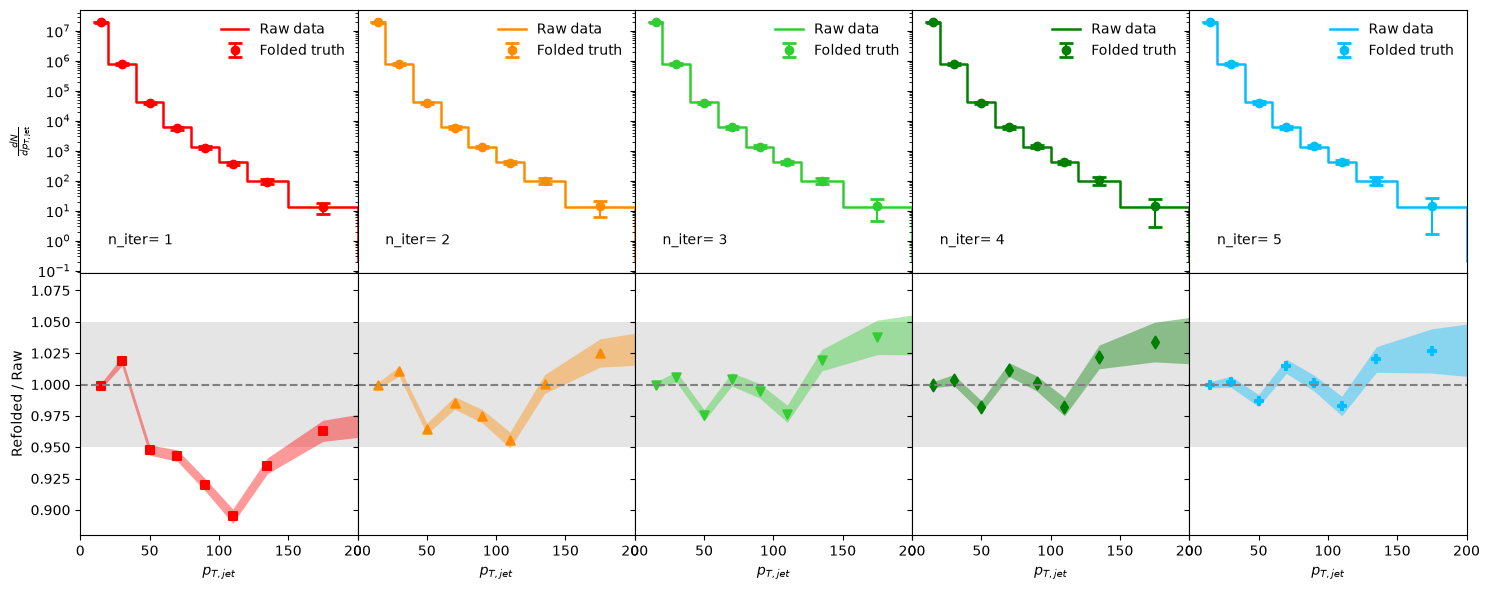

In [12]:
# Data refolding - w/ purity + efficiency corrections
plot_closure_test(n_iter, bincenters, binning, binwidths, y_raw, y_refolded, y_refolded_err, L_colors, L_markers, "Raw data", "Folded truth", False)


In [ ]:
# Binning setup & Plotting

if hasattr(h1_reco, "axes"):
    bin_edges = h1_reco.axes[0].edges
else:
    bin_edges = np.arange(len(y_reco) + 1)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]}
)

# Upper panel: Distributions
ax1.step(bin_edges[:-1], y_reco, where='post', label='Detector-level MC / Data (Reco)', color='black', lw=1.8)
ax1.step(bin_edges[:-1], y_refolded, where='post', label='Refolded ($\mathbf{RM} \\times \mathbf{Truth}$)', color='crimson', ls='--')
ax1.set_ylabel("Yield / A.U.")
ax1.set_yscale("log")
ax1.legend(frameon=False)
ax1.grid(True, which='both', linestyle=':', alpha=0.5)
ax1.set_title(f"RooUnfold Refolding Test (Iter {selected_iter + 1})")

# Lower panel: Ratio
ratio = np.divide(y_refolded, y_reco, out=np.zeros_like(y_refolded), where=y_reco!=0)

ax2.axhline(1.0, color='gray', linestyle='--')
ax2.step(bin_edges[:-1], ratio, where='post', color='crimson', lw=1.5)
ax2.set_xlabel("Reco Observable")
ax2.set_ylabel("Refolded / Reco")
ax2.set_ylim(0.7, 1.3)
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


In [5]:
proj = lambda a : a.values()
proj_err = lambda a : a.errors()
proj_err_unf = lambda a : np.sqrt(a.errors()**2 + a.values())

theta0_G = proj(h1_gen)
theta0_S = proj(h1_reco)
theta_unknown_G = proj(h1_true)
theta_unknown_S = proj(h1_raw)

root_setp = ""

values, edges = h1_gen.to_numpy()
print(edges)
print(values)
print(theta0_G)
print()
print(theta0_S)
print()
print(theta_unknown_G)
print(theta_unknown_S)

theta_unfolded = [proj(a) for a in h1_unfolded]

theta0_G_err = proj_err(h1_gen)
theta0_S_err = proj_err(h1_reco)
theta_unknown_G_err = proj_err(h1_true)
theta_unknown_S_err = proj_err(h1_raw)

theta_unfolded_err = [proj_err_unf(a) for a in h1_unfolded]


[ 10.  20.  40.  60.  80. 100. 120. 150. 200. 500.]
[7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00]
[7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00]

[5.57195604e+05 4.16105626e+04 2.00059865e+03 2.77852631e+02
 6.12406949e+01 1.76404427e+01 6.52408235e+00 1.53465726e+00
 1.54922685e-01]

[7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00]
[5.57195604e+05 4.16105626e+04 2.00059865e+03 2.77852631e+02
 6.12406949e+01 1.76404427e+01 6.52408235e+00 1.53465726e+00
 1.54922685e-01]


In [6]:
# print total number of jets
print("######### UNFOLDED JETS #########")
print(binning)
print(theta_unfolded[-1])
print(theta_unfolded_err[-1])
for i in range(len(theta_unfolded)):
    print("\t i={}, {} +/- {}".format(i, np.sum(theta_unfolded[i]), np.sum(theta_unfolded_err[i])))
print("total det jets : {} \n".format(np.sum(theta_unfolded[-1]) ))

print("######### DATA TRUTH JETS #########")
print(binning)
print(theta_unknown_G)
print("total truth jets : {} \n".format(np.sum(theta_unknown_G) ))

print("######### DATA RAW JETS #########")
print(binning_reco)
print(theta_unknown_S)
print("total truth jets : {}".format(np.sum(theta_unknown_S) ))

# TODO propagate error from here to actaul eec calculation
# also why is it exact?!

######### UNFOLDED JETS #########
[ 10.  20.  40.  60.  80. 100. 120. 150. 200. 500.]
[2.51356404e+08 2.65094120e+07 1.88261616e+06 2.84214344e+05
 6.22853920e+04 1.98745641e+04 9.28134668e+03 3.29965147e+03
 8.24875069e+02]
[24864.03020601  8135.67602239  2119.67952626   761.42080933
   338.88962436   183.31291948   126.55992388    75.46768878
    37.9343142 ]
	 i=0, 280251235.0807461 +/- 33169.246987166545
	 i=1, 280156172.6879262 +/- 35284.18381087363
	 i=2, 280128212.17004764 +/- 36642.97103469896
total det jets : 280128212.17004764 

######### DATA TRUTH JETS #########
[ 10.  20.  40.  60.  80. 100. 120. 150. 200. 500.]
[7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00]
total truth jets : 780062.0124196276 

######### DATA RAW JETS #########
[ 10.  20.  40.  60.  80. 100. 120. 150. 200. 500.]
[5.57195604e+05 4.16105626e+04 2.00059865e+03 2.77852631e+02
 6.12406949e+01 1.76404427e+01 6.52408235e

[ 15.  30.  50.  70.  90. 110. 135. 175. 350.] [7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00] [ 10.  20.  20.  20.  20.  20.  30.  50. 300.]
[ 15.  30.  50.  70.  90. 110. 135. 175. 350.] [5.57195604e+05 4.16105626e+04 2.00059865e+03 2.77852631e+02
 6.12406949e+01 1.76404427e+01 6.52408235e+00 1.53465726e+00
 1.54922685e-01] [ 10.  20.  20.  20.  20.  20.  30.  50. 300.]


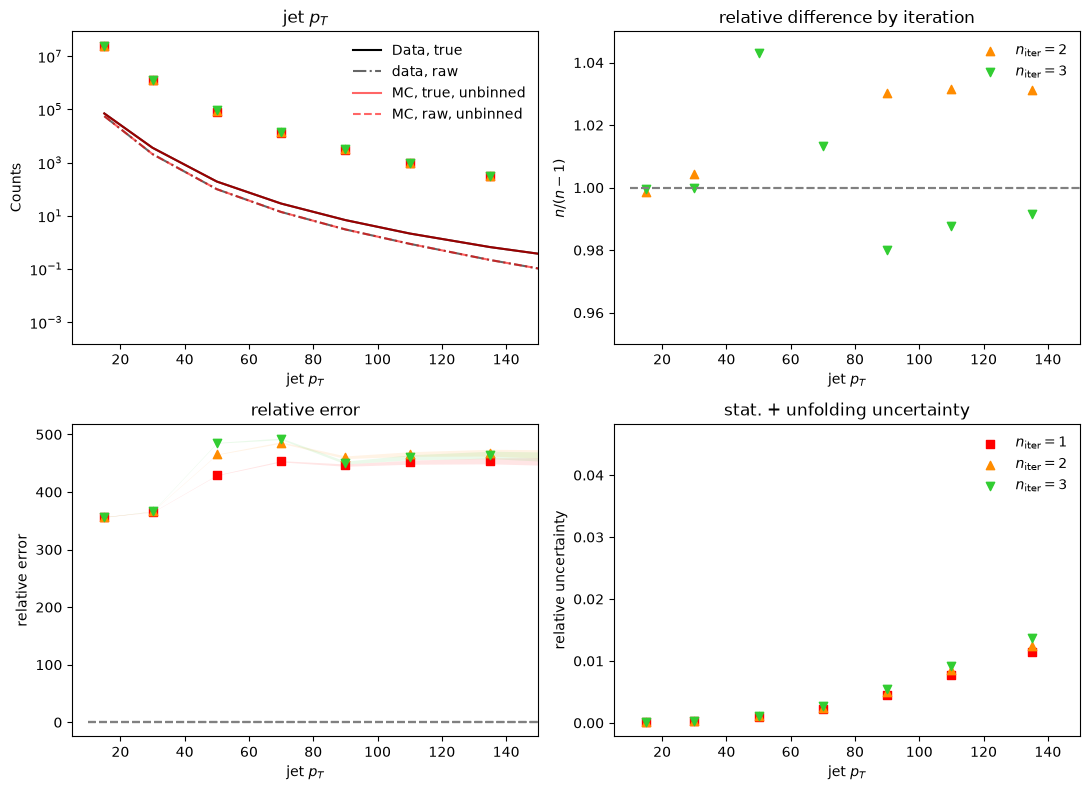

In [7]:
############################## UNFOLDED DISTRIBUTIONS ############################
# EEC distros

it = 3

fig, axes = plt.subplots(2, 2, figsize=(11,8))

pt_lims = [5, 150]

# COL 1: raw jet pt distribution WITH relative error over data, true underneath
ax = axes[0, 0]

print(bincenters, theta_unknown_G, binwidths)
ax.plot(bincenters, theta_unknown_G / binwidths, color='black',label="Data, true")

# comparison with data raw
print(bincenters_reco, theta_unknown_S, binwidths_reco)
ax.plot(bincenters_reco, theta_unknown_S / binwidths_reco, color='black', linestyle='dashdot', alpha=0.6, label="data, raw")

# comparison with MC true, MC det
ax.plot(bincenters, theta0_G / binwidths, color='red', alpha=0.6, label="MC, true, unbinned")

ax.plot(bincenters_reco, theta0_S / binwidths_reco, color='red', alpha=0.6, linestyle='dashed', label="MC, raw, unbinned")

# comparison with published distribution
# norm_hep = 0.2 * np.dot(binwidths, theta0_G) / np.dot(np.diff(hep_compare_x), hep_compare_y[:-1]) # normalize to MC, true
# ax.plot(hep_compare_x, hep_compare_y * norm_hep,color='green',label="published",lw=1)

# comparison with Wenqing's PythiaMC distribution
# norm = (theta_unfolded[-1][3] / h1_compare[2]) * 0.97
# h1_compare_normed = h1_compare * norm
#ax.step(binning[:-1], h1_compare_normed, where="post",color='grey',label="PythiaMC, compare",lw=1)

for iteration in range(it):

    ax.scatter(bincenters, theta_unfolded[iteration] / binwidths,color=L_colors[iteration],marker=L_markers[iteration],lw=1)

    ax.set_ylabel("Counts")
    ax.set_title(labels)
    ax.set_xlabel(labels)
    ax.set_yscale('log')

    ax.legend(frameon=False)

    ax.set_xlim(pt_lims)

# row below with the error
ax = axes[1, 0]

ax.hlines(y=0, xmin=binning[0], xmax=binning[len(binning)-1], color='grey', linestyle='--')

for iteration in range(it):

    yvals, yerrs = get_ratio_safe(theta_unfolded[iteration], theta_unknown_G, \
                                      numerr=theta_unfolded_err[iteration], denomerr=theta_unknown_G_err, filler=1)
    yvals = yvals - 1

    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label=f"$n_\mathrm{{iter}}={iteration+1}$",lw=1)

    ax.fill_between(bincenters, yvals-yerrs, yvals+yerrs, alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)

    ax.hlines(y=0, xmin=binning[0], xmax=binning[len(binning)-1], color='grey', linestyle='--')
    
    ax.set_title("relative error")
    ax.set_xlabel(labels)
    ax.set_ylabel("relative error")

    #ax.set_ylim([-0.3, 0.3])
    ax.set_xlim(pt_lims)


# COL 2: convergence plot (n / n - 1)
ax = axes[0, 1]

for iteration in range(1,it):

    yvals = safe_divide(theta_unfolded[iteration], theta_unfolded[iteration-1], filler=1)
    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label=f"$n_\mathrm{{iter}}={iteration+1}$",lw=1)

    ax.hlines(y=1, xmin=binning[0], xmax=binning[len(binning)-1], color='grey', linestyle='--')

    ax.set_title('relative difference by iteration')
    ax.set_xlabel(labels)
    ax.set_ylabel("$ n / (n-1)$")
    ax.legend(frameon=False)

    ax.set_ylim([0.95, 1.05])
    ax.set_xlim(pt_lims)


# COL 3: statistical error %
ax = axes[1, 1]

for iteration in range(it):
    
    yvals = safe_divide(theta_unfolded_err[iteration], theta_unfolded[iteration])
    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label=f"$n_\mathrm{{iter}}={iteration+1}$",lw=1)

    ax.set_title('stat. + unfolding uncertainty')
    ax.set_xlabel(labels)
    ax.set_ylabel("relative uncertainty")
    ax.legend(frameon=False)

    ax.set_xlim(pt_lims)


fig.tight_layout()
plt.show()